# 2. Quality control

*Page 2 of 9.* [previous: 1. The question and the data](https://robinson-vidva.github.io/mb-methylation-xai/01_question_and_data.html) | [index](https://robinson-vidva.github.io/mb-methylation-xai/) | [next: 3. Classification](https://robinson-vidva.github.io/mb-methylation-xai/03_classification.html)

Quality control answers one question before any modelling: is the data what it claims to be?
Four checks are run. Each is standard for methylation arrays and each is explained once.

## 1. Which CpG sites are kept, and why

Not every probe on the array is usable. Probes on the X and Y chromosomes track sex, not tumour biology.
Probes that overlap a common SNP measure the genotype, not methylation. The 450k array also carries
about 3,000 "ch" probes that measure non-CpG methylation. Probes with a missing value in any tumour
would need imputation. The table counts what survives each step.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display
from pathlib import Path
TAB = Path('../results/tables')
FIG = Path('../results/figures')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 90)

In [2]:
pd.read_csv(TAB / 'qc_probe_funnel.csv')

,step,probes
0,probes on the Illumina 450k array (GPL13534 manifest),485512
1,probes in the deposited GSE85212 beta matrix,321174
2,"of these, on autosomes (the submitters had already removed X and Y)",321174
3,without a known SNP at the probe,310101
4,cg probes only (ch probes removed),308020
5,without any missing value across 763 tumours,308020
6,also present in the external GSE54880 matrix,308020
7,selected by training-set variance for modelling,10000


The deposited matrix already lacked the X and Y chromosomes and most of the array. The authors
had filtered it before upload. Removing SNP probes and ch probes leaves 308,020 CpGs, all complete,
all present in the external cohort as well. Modelling uses the 10,000 most variable of these,
chosen on the training split only so that the test split cannot leak into feature selection.

## 2. Does every tumour look like a methylation profile?

A healthy array gives a bimodal beta distribution: most sites are either unmethylated (near 0) or
methylated (near 1). A flat or shifted distribution signals a failed hybridisation or degraded DNA.
The figure overlays 15 random tumours per subgroup. The table summarises every tumour.

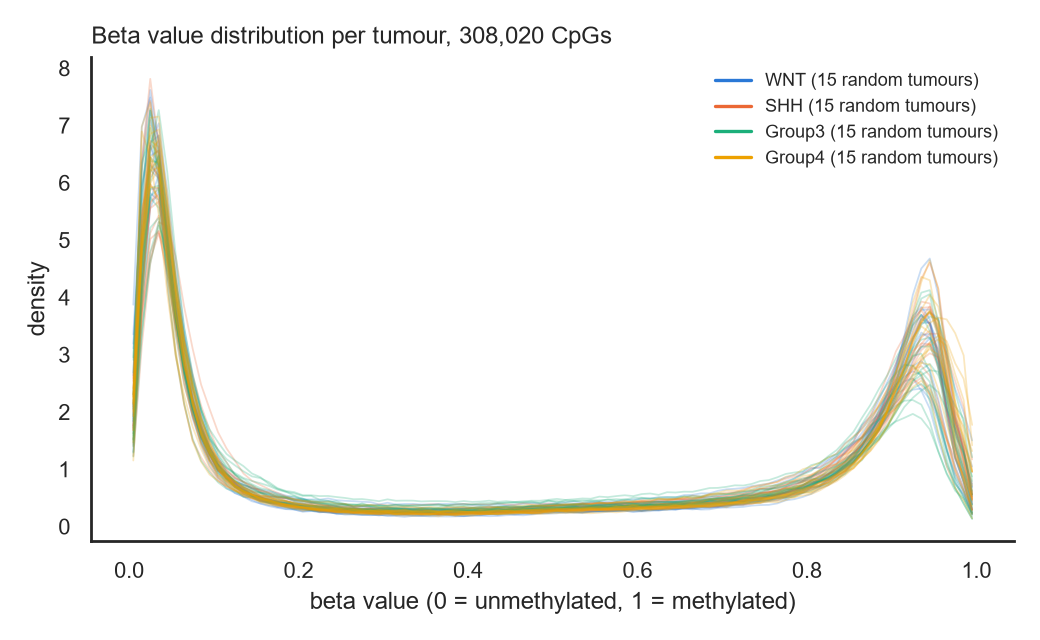

mean_beta               median_beta               sd_beta               fraction_below_0.2               fraction_above_0.8              
            mean    min    max        mean    min    max    mean    min    max               mean    min    max               mean    min    max
group                                                                                                                                           
Group3     0.458  0.315  0.562       0.438  0.108  0.763   0.382  0.339  0.408              0.423  0.326  0.570              0.334  0.170  0.482
Group4     0.472  0.407  0.542       0.477  0.253  0.735   0.394  0.349  0.414              0.426  0.361  0.485              0.369  0.225  0.467
SHH        0.464  0.395  0.557       0.456  0.229  0.768   0.384  0.347  0.410              0.419  0.345  0.485              0.341  0.232  0.485
WNT        0.470  0.428  0.508       0.472  0.301  0.622   0.392  0.368  0.417              0.425  0.364  0.472              0.366  0.304  0.440

In [3]:
display(Image(FIG / 'qc_beta_density.png'))
stats = pd.read_csv(TAB / 'qc_sample_stats.csv', index_col=0)
stats.groupby('group')[['mean_beta', 'median_beta', 'sd_beta', 'fraction_below_0.2', 'fraction_above_0.8']].agg(['mean', 'min', 'max']).round(3)

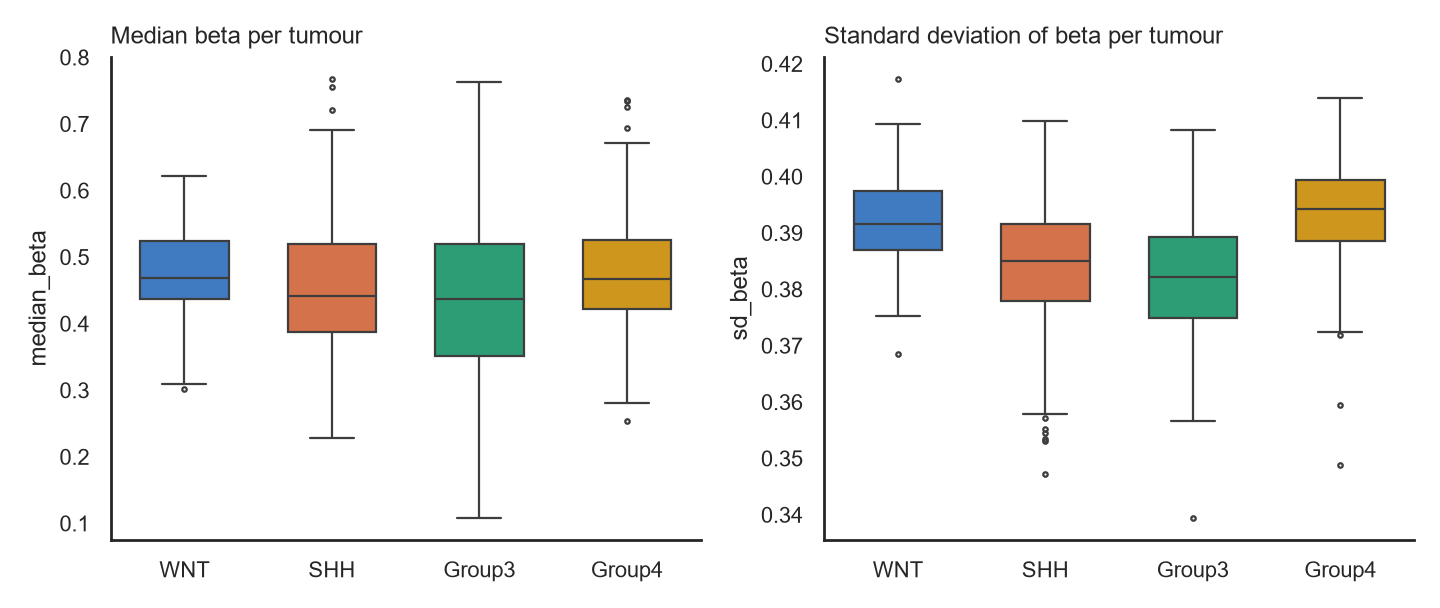

In [4]:
display(Image(FIG / 'qc_sample_medians.png'))

All 763 tumours are bimodal and no tumour stands apart. Group 3 tumours have a slightly lower
mean beta than the other groups, which fits the known global hypomethylation of Group 3.

## 3. The external cohort: failed probes and FFPE

Hovestadt et al. 2013 deposited detection p-values alongside the beta values. A detection p-value
tests whether a probe's signal is above background. Probes with p above 0.01 are treated as missing
and were imputed with the training median before classification. Formalin-fixed material (FFPE)
fragments DNA and raises the failure rate, so the check is split by material.

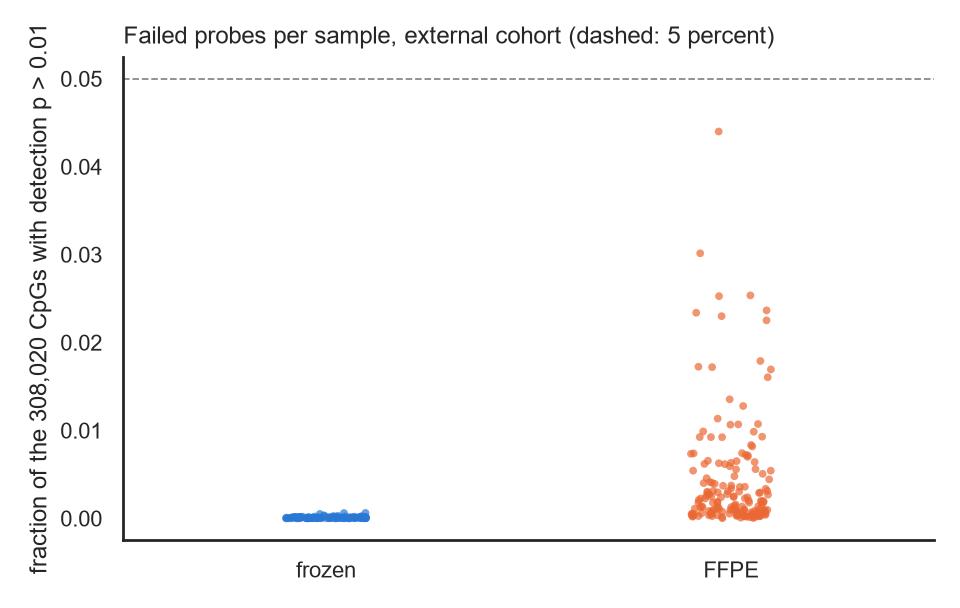

,count,mean,std,min,25%,50%,75%,max
material,,,,,,,,
FFPE,169.0,0.0044,0.0065,0.0,0.0006,0.0020,0.0056,0.0440
frozen,115.0,0.0001,0.0001,0.0,0.0000,0.0001,0.0001,0.0006


In [5]:
det = pd.read_csv(TAB / 'qc_external_detection.csv', index_col=0)
display(Image(FIG / 'qc_external_detection.png'))
det.groupby('material')['fraction_failed_of_modelled_cpgs'].describe().round(4)

Frozen samples lose almost nothing. FFPE samples lose a median of 0.2 percent of the modelled CpGs,
and the worst sample loses 4.4 percent, below the 5 percent line at which a sample would be dropped.
Imputing these few sites with the training median is a small intervention. Section 3 of the
classification page shows that FFPE samples classify as well as frozen ones.

## 4. Sex check

Females carry two X chromosomes and one is inactivated by methylation. Mean methylation over X
chromosome CpGs is therefore higher in females. This is a cheap check that samples and metadata were
not swapped. The Cavalli deposit has no X probes and no sex annotation, so the check runs on the
external cohort, which has both.

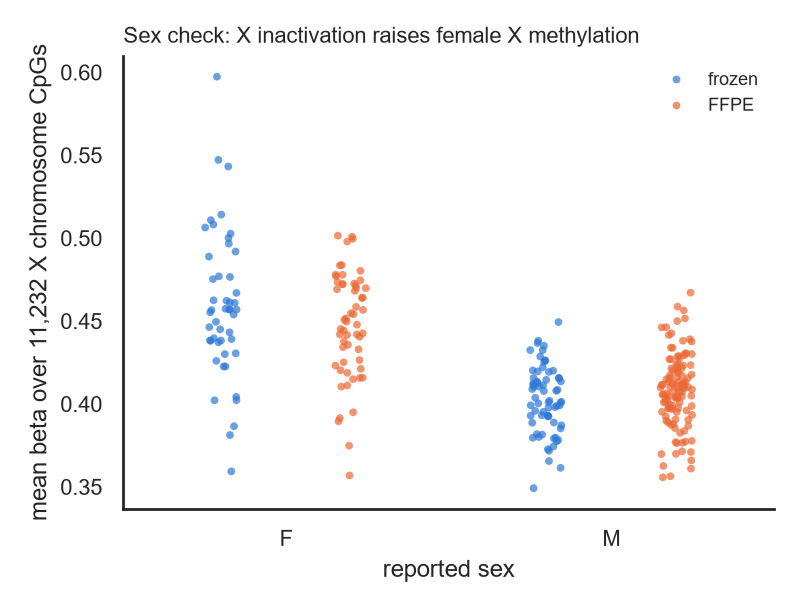

,count,mean,std,min,25%,50%,75%,max
sex,,,,,,,,
F,105.0,0.453,0.038,0.357,0.431,0.454,0.474,0.597
M,179.0,0.406,0.022,0.349,0.393,0.407,0.420,0.467


In [6]:
display(Image(FIG / 'qc_external_sex_check.png'))
pd.read_csv(TAB / 'qc_external_sex_check.csv', index_col=0).groupby('sex')['mean_beta_chrX'].describe().round(3)

Reported sex and X methylation agree for the large majority. A few FFPE samples sit between the two
clusters, which is expected with degraded DNA. No sample is on the wrong side by a clear margin.

## 5. Does the main structure of the data match the labels?

Principal component analysis (PCA) finds the directions of largest variation in the 10,000 modelled
CpGs. If the subgroups are real and the labels are right, they should separate along the first
components without any model. The right panel projects the external cohort onto the same axes to see
whether a different laboratory, and FFPE material, lands in the same place.

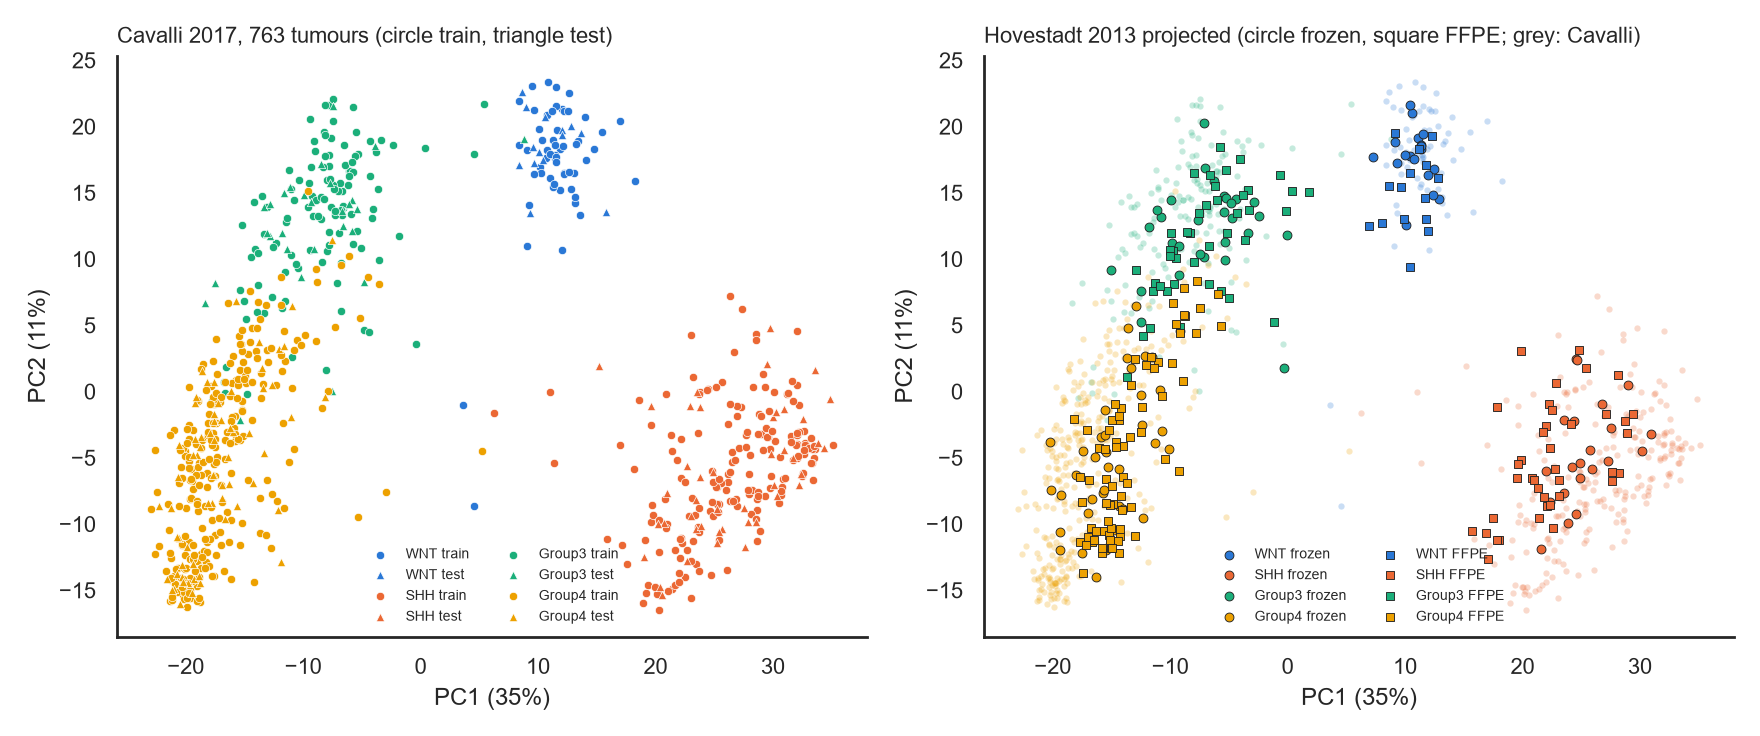

,0,1,2,3,4,5,6,7,8,9
component,1.0000,2.0000,3.000,4.0000,5.0000,6.0000,7.0000,8.0000,9.0000,10.0000
variance_explained,0.3503,0.1137,0.068,0.0409,0.0382,0.0214,0.0141,0.0127,0.0103,0.0085


In [7]:
display(Image(FIG / 'qc_pca.png'))
pd.read_csv(TAB / 'qc_pca_variance.csv').T

The first two components carry almost half of the variance and separate the four subgroups
without supervision. WNT and SHH are tight. Group 3 and Group 4 touch, which is the known difficulty.
The external tumours, frozen and FFPE alike, fall on top of their Cavalli subgroups. There is no
visible laboratory or material batch effect on these axes, so a classifier trained on Cavalli has a
fair chance on Hovestadt.

*Page 2 of 9.* [previous: 1. The question and the data](https://robinson-vidva.github.io/mb-methylation-xai/01_question_and_data.html) | [index](https://robinson-vidva.github.io/mb-methylation-xai/) | [next: 3. Classification](https://robinson-vidva.github.io/mb-methylation-xai/03_classification.html)